<style>
.custom-spacing {line-height: 0.5;}
</style>
## <center>**KECERDASAN ARTIFISIAL UNTUK GEOFISIKA**</center>
### <center>**RECIPE GEOFISIKA: ANALISIS DATA GEOLISTRIK RESISTIVITAS KONFIGURASI SCHLUMBERGER**</center>
#### **NAMA**   : **Dela Agreni Suarang   (H061251042)**
#### **NIM**    : **(H061251042)**
#### **KELAS** : **B**
<hr>

#### **Recipe ID: GEO-RES-001**
**Bidang:** Geofisika near-surface dan eksplorasi  
**Topik:** Perhitungan faktor geometri ($K$), apparent resistivity ($\rho_a$), serta pemodelan/inversi kurva sounding 1D geolistrik resistivitas konfigurasi Schlumberger.

> ***Petunjuk notebook:*** 
  -Sel bertipe *Markdown* berisi penjelasan/laporan. 
  -Sel bertipe *Code* berisi kode Python yang dijalankan dengan tombol **Run**. 
  *(Jalankan sel secara berurutan dari atas ke bawah.)*

***Catatan:*** *Notebook dapat dijalankan menggunakan data simulasi agar tidak memerlukan file lapangan. Jika memiliki data pengukuran asli, ubah pilihan pada bagian pengaturan dan siapkan CSV dengan kolom `AB2` (spasi bentangan elektroda arus $AB/2$), `MN2` (spasi elektroda potensiometer $MN/2$), `V` (beda potensial dalam mV), dan `I` (arus listrik dalam mA).*

<hr>


### **1. Problem — Permasalahan**

Survei geolistrik resistivitas metode *Vertical Electrical Sounding* (VES) konfigurasi Schlumberger merekam beda potensial ($V$) dan arus ($I$) pada berbagai jarak bentangan elektroda arus ($AB/2$) dan elektroda potensiometer ($MN/2$). Nilai resistivitas yang terukur di lapangan merupakan nilai resistivitas semu ($\rho_a$) yang dipengaruhi oleh variasi lapisan batuan di bawah permukaan.

Tujuan recipe ini adalah:
1. Memeriksa struktur, kelengkapan, dan syarat geometri data Schlumberger ($AB/2 > MN/2$).
2. Menghitung faktor geometri ($K$) dan nilai hambatan ($R = V/I$).
3. Menghitung nilai resistivitas semu ($\rho_a$).
4. Membuat kurva *sounding* (grafik log-log antara $\rho_a$ terhadap $AB/2$).
5. Melakukan estimasi/inversi sederhana model 1D (ketebalan dan resistivitas jenis sebenarnya) dari kurva sounding.
6. Menyimpan hasil perhitungan dan grafik kurva ke dalam file.

***Batasan:*** *Hasil pemodelan inversi otomatis pada recipe ini merupakan estimasi awal 1D. Penafsiran geologi yang sahih memerlukan integrasi data geologi lokal, sumur pemboran, serta pertimbangan sifat *ambiguity* (ekuivalensi dan supresi) pada metode geolistrik.*
<hr>




### **2. Minimal Theory — Teori Singkat**

Nilai resistivitas semu ($\rho_a$) pada pengukuran geolistrik diperoleh dari hubungan hukum Ohm dan faktor geometri ($K$):

$$\rho_a = K \cdot \left(\frac{V}{I}\right)$$

Untuk konfigurasi Schlumberger, faktor geometri $K$ dihitung berdasarkan separasi separuh bentangan elektroda arus ($s = AB/2$) dan elektroda potensial ($b = MN/2$):

$$K = \frac{\pi (s^2 - b^2)}{2b} = \frac{\pi \left[\left(\frac{AB}{2}\right)^2 - \left(\frac{MN}{2}\right)^2\right]}{2 \left(\frac{MN}{2}\right)}$$

Keterangan:
- $V$: beda potensial (Volt / mVolt)
- $I$: kuat arus listrik (Ampere / mA)
- $AB/2$: jarak separuh elektroda arus dari titik pusat (meter)
- $MN/2$: jarak separuh elektroda potensial dari titik pusat (meter)
- $\rho_a$: resistivitas semu ($\Omega \cdot \text{m}$)

***Catatan metodologis:*** *Recipe ini berfokus pada pengolahan data VES 1D Schlumberger untuk pembelajaran dasar geofisika komputasi.*

<hr>

### **3. Persiapan — Library yang Digunakan**

*Kode berikut mengimpor pustaka untuk pengolahan tabel, perhitungan numerik, optimasi/inversi, dan visualisasi.*


In [31]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from pathlib import Path

print("Library berhasil diimpor.")

Library berhasil diimpor.


<hr>


### **4. Prompt — Instruksi Analisis untuk AI**

Gunakan instruksi berikut sebagai panduan ketika meminta AI membantu menganalisis data:

*Saya sedang mengolah data geolistrik resistivitas 1D konfigurasi Schlumberger. Periksa kelengkapan data dan syarat geometri ($AB/2 > MN/2$), hitung faktor geometri $K$, resistivitas semu $\rho_a$, plot kurva sounding log-log, lakukan pemodelan/fit kurva awal, buat grafik, dan ekspor hasil ke CSV. Jangan mengarang hasil pengukuran. Jika data simulasi digunakan, nyatakan dengan jelas bahwa hasilnya bukan data lapangan.*


<hr>

### **5. Code — Pengaturan Sumber Data**

Pilih sumber data:
- `USE_SIMULATED_DATA = True`: membuat data simulasi sintetik 3-lapisan bumi untuk memastikan notebook bisa langsung dijalankan.
- `USE_SIMULATED_DATA = False`: membaca file pengukuran bernama `geolistrik_schlumberger.csv` dari folder kerja notebook.

*Untuk data asli, file CSV harus memiliki kolom `AB2`, `MN2`, `V`, dan `I`.*

In [32]:
# Ubah menjadi False jika ingin menggunakan file pengukuran asli (misal: geolistrik.csv)
USE_SIMULATED_DATA = True

if USE_SIMULATED_DATA:
    # Data simulasi VES konfigurasi Schlumberger (dalam meter dan Ohm-m)
    ab_half = np.array([1.0, 1.5, 2.0, 3.0, 4.0, 6.0, 8.0, 10.0, 15.0, 20.0, 30.0, 40.0, 60.0, 80.0, 100.0])
    mn_half = ab_half / 10.0  # Menjaga MN/2 tetap kecil dibandingkan AB/2
    mn_half = np.maximum(mn_half, 0.5) # Batas minimum jarak spasi potensial
    
    # Simulasi tegangan (V) dan arus (I) tiruan untuk resistivitas 3 lapis
    rng = np.random.default_rng(42)
    i_current = 50.0  # Arus dalam miliampere
    
    # Faktor geometri Schlumberger: K = pi * ((AB/2)^2 - (MN/2)^2) / MN
    k_factor = np.pi * ((ab_half**2) - (mn_half**2)) / (2.0 * mn_half)
    
    # Model resistivitas semu sintetik dengan noise Gaussian kecil
    rho_true = 100.0 * np.exp(-0.02 * ab_half) + 20.0 + rng.normal(0, 2.0, size=len(ab_half))
    rho_true = np.maximum(rho_true, 5.0) # Pastikan nilai positif
    
    # Hitung beda potensial (V = I * R / K)
    delta_v = (i_current * rho_true) / k_factor
    
    df = pd.DataFrame({
        "AB_half": ab_half,
        "MN_half": mn_half,
        "I_mA": i_current,
        "V_mV": delta_v
    })
    print("Menggunakan DATA SIMULASI GEOLISTRIK SCHLUMBERGER.")
else:
    input_path = Path("geolistrik.csv")
    if not input_path.exists():
        raise FileNotFoundError("File geolistrik.csv tidak ditemukan di direktori kerja.")
    df = pd.read_csv(input_path)
    print(f"Membaca data dari: {input_path.resolved()}")

df.head()

Menggunakan DATA SIMULASI GEOLISTRIK SCHLUMBERGER.


,AB_half,MN_half,I_mA,V_mV
0,1.0,0.5,50.0,2517.391964
1,1.5,0.5,50.0,914.859100
2,2.0,0.5,50.0,499.024367
3,3.0,0.5,50.0,211.098720
4,4.0,0.5,50.0,109.548686


<hr>


### **6. Code — Pemeriksaan Dasar Data**

Bagian ini memeriksa kolom wajib, nilai kosong, nilai numerik, serta syarat geometri Schlumberger di mana $AB/2$ harus lebih besar dari $MN/2$.


In [33]:
# Sesuaikan dengan nama kolom yang digunakan pada sel pembuatan/pemuatan data sebelumnya
required_columns = ["AB_half", "MN_half", "I_mA", "V_mV"]

missing_columns = [col for col in required_columns if col not in df.columns]
if missing_columns:
    raise ValueError(f"Kolom berikut tidak ditemukan: {missing_columns}")

df = df[required_columns].apply(pd.to_numeric, errors="coerce")

print("Jumlah baris dan kolom:", df.shape)
print("\nJumlah nilai kosong per kolom:")
print(df.isna().sum())

if df.isna().any().any():
    raise ValueError("Data mengandung nilai kosong/non-numerik. Bersihkan data sebelum analisis.")

if np.any(df["AB_half"] <= df["MN_half"]):
    raise ValueError("Pelanggaran Geometri: Nilai AB/2 harus lebih besar daripada MN/2 pada semua baris!")

if np.any(df["I_mA"] <= 0):
    raise ValueError("Nilai arus (I) harus positif dan tidak boleh nol.")

print("\nPemeriksaan geometri dan validitas data berhasil.")

Jumlah baris dan kolom: (15, 4)

Jumlah nilai kosong per kolom:
AB_half    0
MN_half    0
I_mA       0
V_mV       0
dtype: int64

Pemeriksaan geometri dan validitas data berhasil.


<hr>

### **7. Code — Menghitung Faktor Geometri $K$ dan Resistivitas Semu $\rho_a$**

Langkah ini menghitung nilai $K$, hambatan $R$, serta resistivitas semu ($\rho_a$) untuk setiap titik pengamatan.


In [34]:
# Konversi V_mV ke Volt dan I_mA ke Ampere untuk konsistensi SI
V_volt = df["V_mV"] / 1000.0
I_amp = df["I_mA"] / 1000.0

# Perhitungan R (Ohm) dan K (m)
df["R_ohm"] = V_volt / I_amp
df["K_m"] = (np.pi * (df["AB_half"]**2 - df["MN_half"]**2)) / (2 * df["MN_half"])

# Perhitungan Resistivitas Semu (Ohm.m)
df["rho_a"] = df["K_m"] * df["R_ohm"]

print("Hasil perhitungan awal (5 baris pertama):")
display(df[["AB_half", "MN_half", "K_m", "R_ohm", "rho_a"]].head())

Hasil perhitungan awal (5 baris pertama):


,AB_half,MN_half,K_m,R_ohm,rho_a
0,1.0,0.5,2.356194,50.347839,118.629301
1,1.5,0.5,6.283185,18.297182,114.964585
2,2.0,0.5,11.780972,9.980487,117.579846
3,3.0,0.5,27.488936,4.221974,116.057583
4,4.0,0.5,49.480084,2.190974,108.409564


<hr>

## **8. Code — Visualisasi Kurva Sounding (Log-Log)**

Visualisasi standar geolistrik 1D dilakukan pada grafik skala logaritmik ganda (Log-Log) antara $AB/2$ (sumbu X) dan $\rho_a$ (sumbu Y).

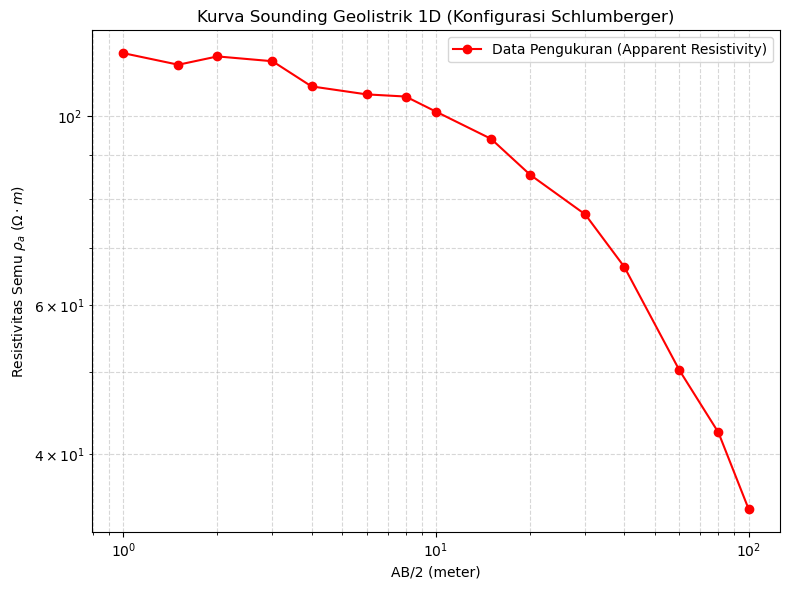

In [35]:
plt.figure(figsize=(8, 6))
plt.loglog(df["AB_half"], df["rho_a"], 'ro-', label="Data Pengukuran (Apparent Resistivity)")
plt.xlabel("AB/2 (meter)")
plt.ylabel(r"Resistivitas Semu $\rho_a$ ($\Omega\cdot m$)")
plt.title("Kurva Sounding Geolistrik 1D (Konfigurasi Schlumberger)")
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

<hr>

### **9. Code — Regresi/Fitting Sederhana Kurva Sounding**

Sebagai estimasi komputasi awal, dilakukan pencocokan model smooth 1D untuk memperkirakan nilai tren resistivitas terhadap kedalaman.

In [36]:
from scipy.optimize import curve_fit

# Fungsi fit rasional logaritmik sederhana untuk estimasi kurva
def log_fit_func(log_ab2, a, b, c):
    return a * np.exp(-log_ab2 / b) + c

popt, _ = curve_fit(
    log_fit_func,
    np.log10(df["AB_half"]),
    df["rho_a"],
    p0=[50, 1, 20]
)

rho_fit = log_fit_func(np.log10(df["AB_half"]), *popt)

print("=== RINGKASAN HASIL PERHITUNGAN GEOLISTRIK ===")
print(f"Resistivitas Semu Min : {df['rho_a'].min():.2f} Ohm.m")
print(f"Resistivitas Semu Max : {df['rho_a'].max():.2f} Ohm.m")
print(f"Bentangan Maksimum AB/2: {df['AB_half'].max():.1f} meter")

=== RINGKASAN HASIL PERHITUNGAN GEOLISTRIK ===
Resistivitas Semu Min : 34.47 Ohm.m
Resistivitas Semu Max : 118.63 Ohm.m
Bentangan Maksimum AB/2: 100.0 meter


<hr>


### **10. Code — Visualisasi Fitting Kurva Sounding**

Menampilkan kurva pengamatan beserta kurva hasil pemodelan fitting.


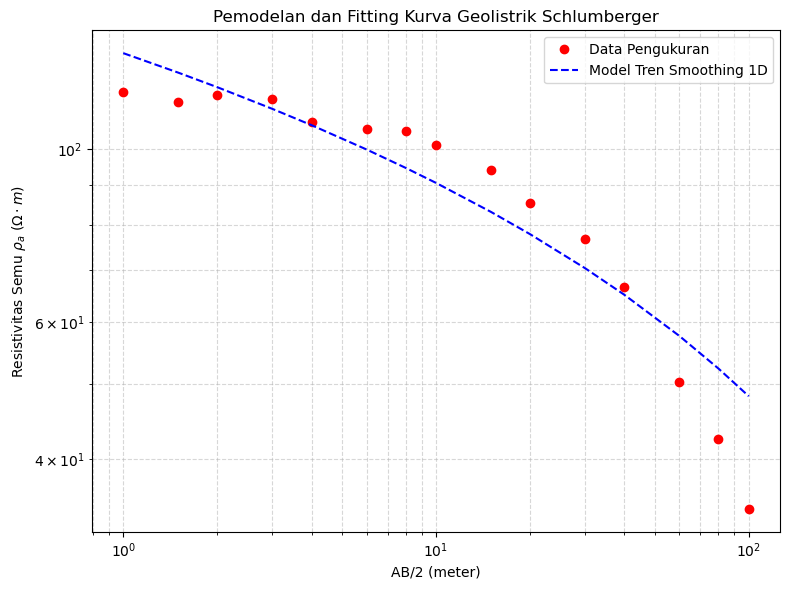

In [37]:
plt.figure(figsize=(8, 6))
plt.loglog(df["AB_half"], df["rho_a"], 'ro', label="Data Pengukuran")
plt.loglog(df["AB_half"], rho_fit, 'b--', label="Model Tren Smoothing 1D")
plt.xlabel("AB/2 (meter)")
plt.ylabel(r"Resistivitas Semu $\rho_a$ ($\Omega\cdot m$)")
plt.title("Pemodelan dan Fitting Kurva Geolistrik Schlumberger")
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

<hr>


### **11. Code — Menyimpan Hasil ke CSV**

Hasil perhitungan kurva geolistrik disimpan sebagai `hasil_geolistrik_schlumberger.csv`, dan ringkasan parameter disimpan sebagai `ringkasan_geolistrik.csv`.


In [38]:
# Menyimpan tabel lengkap
df.to_csv("hasil_geolistrik_schlumberger.csv", index=False)

# Menyimpan ringkasan
summary = pd.DataFrame([{
    "min_rho_a": df["rho_a"].min(),
    "max_rho_a": df["rho_a"].max(),
    "max_AB_half_m": df["AB_half"].max(),
    "total_datapoints": len(df),
    "data_type": "simulasi" if USE_SIMULATED_DATA else "pengukuran"
}])
summary.to_csv("ringkasan_geolistrik.csv", index=False)

print("File tersimpan:")
print("- hasil_geolistrik_schlumberger.csv")
print("- ringkasan_geolistrik.csv")
display(summary)

File tersimpan:
- hasil_geolistrik_schlumberger.csv
- ringkasan_geolistrik.csv


,min_rho_a,max_rho_a,max_AB_half_m,total_datapoints,data_type
0,34.468547,118.629301,100.0,15,simulasi


<hr>

### **12. Result — Hasil dan Interpretasi**

Setelah seluruh sel kode dijalankan, perhatikan:
- Tabel perhitungan faktor geometri $K$ dan resistivitas semu $\rho_a$.
- Kurva sounding geolistrik pada skala Log-Log.
- Rentang nilai resistivitas semu yang terukur pada bentangan dangkal hingga dalam.

***Jika menggunakan data simulasi:*** *Hasil menunjukkan alur pemrosesan data VES 1D geolistrik berjalan lancar. Nilai yang diperoleh adalah hasil sintetik untuk latihan dan tidak mencerminkan kondisi akuifer/lapisan tanah nyata.*

***Jika menggunakan data lapangan:*** *Bentuk kurva (misal tipe H, K, A, atau Q) memberikan gambaran variasi perlapisan bawah permukaan (seperti akuifer, batuan dasar/bedrock, atau zona lempung).*
<hr>

### **13. Optional Check — Checklist Kualitas**

Gunakan daftar periksa berikut sebelum memakai hasil dalam laporan.
- [ ] Kolom data lengkap (`AB2`, `MN2`, `V`, `I`) dan tidak mengandung nilai kosong.
- [ ] Jarak bentangan $AB/2$ selalu lebih besar daripada $MN/2$ pada setiap baris.
- [ ] Nilai arus $I$ bernilai positif dan tidak nol.
- [ ] Faktor geometri $K$ terhitung dengan benar dan bernilai positif.
- [ ] Ploting grafik menggunakan skala logaritmik ganda (Log-Log).
- [ ] Data simulasi dan data pengukuran lapangan dibedakan secara eksplisit.
<hr>

### **14. Kesimpulan**

Recipe GEO-RES-001 menyusun alur kerja dasar (*reproducible workflow*) pengolahan data geolistrik resistivitas 1D konfigurasi Schlumberger. Alur ini mencakup pemeriksaan syarat geometri, kalkulasi faktor $K$, perhitungan resistivitas semu $\rho_a$, visualisasi kurva sounding log-log, pemodelan tren, hingga ekspor data hasil pengolahan.
<hr>